In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.0011425136987458669 - 0.0001679225863605075im -0.00401674158551372 + 0.004311032583595516im … -0.0030556720553598605 - 0.0004967152489069088im 0.0005944042019529161 + 0.0008418906707149794im; -0.0013098691175803163 - 0.002009484012286624im 0.001968074370153187 - 0.0018707705161777632im … 0.0010486416506590701 - 0.004800582560760535im -0.004316422828321621 + 0.003442331471957927im; 0.006736604707656681 + 0.0012329308563277426im -0.0019888587128635963 + 0.0026624918951069563im … -0.0009366196399260815 + 0.00041248855693442525im -0.00039474653165268354 - 0.001508197729216414im;;; -0.0002035369704410178 + 0.00039617335208286134im -0.0005959703895681527 - 0.002218952317221677im … -0.0006926845999492396 + 0.0026368881871924555im -0.0029116214102231286 + 8.60208169476892e-5im; 0.00011152361738443383 + 0.0006039300924350065im -0.005118427513340834 + 0.0025540169374384763im … -0.0005548541066576667 - 0.00077754298203

In [3]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[4.636860453463613e-6 - 8.932155196351103e-7im -3.876530840043486e-6 - 2.720302323223715e-6im … 1.222789380301961e-6 - 7.150102842690833e-6im 1.2942561689912866e-5 - 9.305204406171774e-7im; 5.588371242906125e-7 - 2.561903081689021e-6im -3.981554271657018e-6 - 2.9528690464862336e-6im … -3.5072072707842314e-6 - 2.372197727980771e-6im 5.785900969852877e-7 + 1.4983022996309122e-6im; 5.541078560226949e-6 - 4.9082771158072175e-6im -9.477022115916226e-6 + 8.191976571028212e-6im … -5.279627381537519e-6 + 7.533552801336566e-7im -4.21282717322969e-6 - 4.549994653510465e-6im;;; 2.582442200717156e-7 - 8.297848119899208e-6im -3.464967797865863e-6 + 4.026453950217009e-6im … -2.724379737900826e-6 + 5.3757283293140584e-6im 5.37139079740367e-6 - 4.468537875733878e-7im; 3.7462088421037966e-6 - 1.0826276426126173e-5im 1.1796553104742666e-5 - 1.6401881539549222e-6im … 4.4278337229682777e-7 + 7.540143476710496e-6im -5.30140871371527

In [4]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)
W1=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [1.3828080343881914 + 0.0im 0.5145258431604365 + 0.0im -0.8747241560848978 + 0.0im -1.4490935738124002 + 0.0im; 0.5510154970017859 + 0.0im 2.2300608933476336 + 0.0im -0.2411137197960871 + 0.0im 1.3905464754729033 + 0.0im; 0.828257585545647 + 0.0im 1.2693390588670401 + 0.0im 0.8763650432137342 + 0.0im 0.19087369338480303 + 0.0im; -0.2394044046728832 + 0.0im 1.0934291597457173 + 0.0im 1.0058750315035967 + 0.0im -0.03295306759341405 + 0.0im]
 [-0.6387209455877707 + 0.0im -1.144572955571658 + 0.0im 1.5386896212381076 + 0.0im 0.6772294924407185 + 0.0im; 0.14122484297252466 + 0.0im -0.663878496480062 + 0.0im -1.1469581427653714 + 0.0im -2.714886416759723 + 0.0im; 0.49726546975031394 + 0.0im -0.987640690507765 + 0.0im 0.42185073092225417 + 0.0im 0.4664457184935563 + 0.0im; -0.26076626513184453 + 0.0im -0.26632833206994333 + 0.0im 0.5759998195357431 + 0.0im -0.49280487432796827 + 0.0im]
 [-2.444382590056188 + 0.0im -0.9614828493335671 + 0.0im -1.6619874214016084

In [5]:
W=W*0.1
W1=W1*0.1
layer=PTC_Layer(hop,W)
layer1=PTC_Layer(hop,W1)
layers = [layer, layer1]

2-element Vector{PTC_Layer}:
 PTC_Layer(Spin_matrix[[0.07430480098236215 + 0.0im 0.19699212579610526 + 0.0im 0.032572736210421054 + 0.0im -0.0034125780138949038 + 0.0im; 0.11052549705040347 + 0.0im -0.02497190071356853 + 0.0im -0.014504669288030151 + 0.0im -0.0041937432194142366 + 0.0im; 0.07245474466968953 + 0.0im -0.01909980686211404 + 0.0im 0.00025191753902247183 + 0.0im 0.17392240386673039 + 0.0im; -0.0426144420147517 + 0.0im 0.056751800038429695 + 0.0im -0.040019593586417455 + 0.0im 0.0210375251868331 + 0.0im], [-0.05745979510552556 + 0.0im 0.053940944187158606 + 0.0im 0.10834439751971539 + 0.0im 0.022092297428819463 + 0.0im; 0.04086756268792872 + 0.0im -0.19671133973437627 + 0.0im 0.06670020423301719 + 0.0im 0.12424562733849438 + 0.0im; -0.21603117289686768 + 0.0im -0.009681049917212456 + 0.0im 0.029646072435086754 + 0.0im 0.03221424226872697 + 0.0im; 0.16952361941602717 + 0.0im 0.13144193662776582 + 0.0im 0.07140532126341301 + 0.0im -0.10591099626269843 + 0.0im], [0.078244966677

In [6]:
norm2(layer(x))

41546.35120241353 + 0.0im

In [7]:
opt=Adam()
opt.α=0.05

0.05

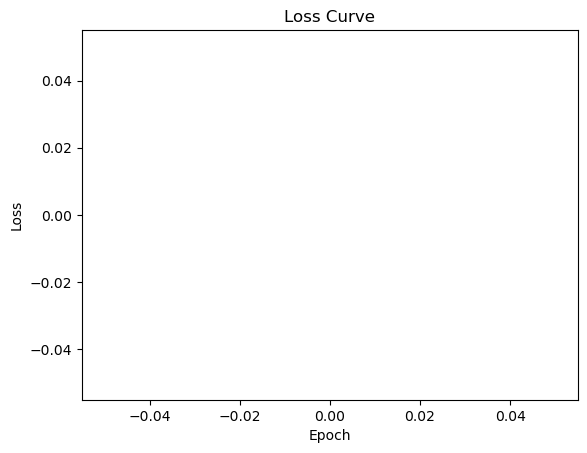

Epoch: 1, Loss: 0.914894156773526 + 0.0im
Epoch: 2, Loss: 0.6829095280186841 + 0.0im
Epoch: 3, Loss: 0.4965466026833989 + 0.0im
Epoch: 4, Loss: 0.48630183823080175 + 0.0im
Epoch: 5, Loss: 0.5015692033716362 + 0.0im
Epoch: 6, Loss: 0.4985154039996279 + 0.0im
Epoch: 7, Loss: 0.47900417917039256 + 0.0im
Epoch: 8, Loss: 0.44429870844749875 + 0.0im
Epoch: 9, Loss: 0.40555988130079906 + 0.0im
Epoch: 10, Loss: 0.37763641862112074 + 0.0im
Epoch: 11, Loss: 0.3472557288239139 + 0.0im
Epoch: 12, Loss: 0.317315373198184 + 0.0im
Epoch: 13, Loss: 0.28277827896533586 + 0.0im
Epoch: 14, Loss: 0.24834121907113324 + 0.0im
Epoch: 15, Loss: 0.2178192834878397 + 0.0im
Epoch: 16, Loss: 0.19559543292551002 + 0.0im
Epoch: 17, Loss: 0.17611492693216013 + 0.0im
Epoch: 18, Loss: 0.15906441813036754 + 0.0im
Epoch: 19, Loss: 0.14942243466860777 + 0.0im
Epoch: 20, Loss: 0.14114947942549297 + 0.0im
Epoch: 21, Loss: 0.13297767600805244 + 0.0im
Epoch: 22, Loss: 0.1269197126543506 + 0.0im
Epoch: 23, Loss: 0.11734000895

In [ ]:
train(opt,layers,x,t,D,epochs=500)


In [ ]:
Lossfunction(layer1(input),target)

1.819677988743451e-5 + 0.0im

In [ ]:
b = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
u = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(b)
gauss_distribution_fermion!(u)
u=deepcopy(b)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.18049499350653392 - 1.1973068523341635im 0.7702180849044304 + 0.06446735932297155im … 0.3580822058839852 - 1.1906681815216904im -0.26984425850025695 + 0.0824188201036985im; 1.1748831777958662 - 0.7495709715195139im -0.47374086760327216 + 0.07117109220105135im … 1.172014362908937 - 0.00048796150403390513im -0.13364425444277284 + 0.6350257615240448im; -1.0683455661456063 - 0.2533193380458577im -1.1995720029586494 - 0.5309655745382286im … -0.8694287840610465 + 1.6760765430440865im -0.2845494847431734 - 0.4470992629373377im;;; -0.5714500784246713 - 0.9578426574495412im 0.3696746065851411 - 0.5072396928003804im … -1.092750691196396 + 0.932467860683335im -0.26227740965189245 - 0.21263526601420366im; 0.6024876686334273 - 0.6420981938428351im -1.1870642792149957 + 0.8747311865025162im … -0.8425030564319906 - 0.44248651980106596im -1.257838864926279 + 0.3855372309442693im; 0.8662469178520258 - 0.7962062990098197im 0.

In [ ]:
@save "PTC_weight.jld2" W  

In [ ]:
source=Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
source[1,1,1,1,1,1]=1


1

In [ ]:
gmres(b,D,source)

Converged at 2-9-th step. eps: 6.210644599710954e-11


In [ ]:
M=[layer1]

1-element Vector{PTC_Layer}:
 PTC_Layer(Spin_matrix[[-0.44277670148910014 + 0.06679946165113161im 0.47375707978184173 - 0.38460372094512363im -0.04444760256354843 + 0.10434418558497532im 0.19776251809975892 - 0.3473803699555078im; 0.2997112066684226 + 0.23752850290010902im 0.45011206227669104 + 0.21136167453878624im 0.22816657128301007 - 0.07152704859902656im -0.5097618543707267 + 0.007230253317449085im; 0.12072084285672048 - 0.3414800329311603im -0.5307241149033571 + 0.7188196096155558im -0.17613144170435713 + 0.2747677296970279im 0.006148274068366921 - 0.6366595391364888im; -0.4829635954127102 - 0.3218236815044972im -0.3700746578024019 - 0.669412756474683im -0.053632735605777214 - 0.19976499680560103im -0.3401086814675833 - 0.2028695364446758im], [-0.0541810641179275 + 0.10351461193954589im -0.02609997787765261 + 0.035098943638748506im -0.0019849464842739382 + 0.03353037669965278im -0.015007312945239135 - 0.011154059987778037im; -0.01556622913292637 - 0.05399596114221548im 0.02067601